# 02 RFM Customer Segmentation
Goal: describe each registered customer by Recency, Frequency and Monetary value, score them into named segments, and propose an action per segment.

## 1. Load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)

PROJECT_DIR = Path.cwd().parent
CLEAN_PATH = PROJECT_DIR / "data" / "processed" / "online_retail_clean.parquet"

df = pd.read_parquet(CLEAN_PATH)
print(df.shape)
df.dtypes

(997099, 9)


Invoice                string
StockCode              string
Description            string
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID             Int64
Country                string
Revenue               float64
dtype: object

## 2. RFM table

In [2]:
cust = df[df["Customer ID"].notna()].copy()

print("Lines:     ", f"{len(cust):,} ({len(cust) / len(df):.1%} of all lines)")
print("Customers: ", f"{cust['Customer ID'].nunique():,}")
print("Revenue:   ", f"{cust['Revenue'].sum() / df['Revenue'].sum():.1%} of total revenue")

Lines:      770,338 (77.3% of all lines)
Customers:  5,839
Revenue:    86.5% of total revenue


In [3]:
snapshot = cust["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
print("Snapshot date:", snapshot.date())

rfm = cust.groupby("Customer ID").agg(
    last_purchase = ("InvoiceDate", "max"),
    frequency = ("Invoice", "nunique"),
    monetary = ("Revenue", "sum"),
)
rfm["recency"] = (snapshot - rfm["last_purchase"].dt.normalize()).dt.days
rfm = rfm[["recency", "frequency", "monetary"]]

print("Customers:", len(rfm))
print("One-time buyers:", f"{(rfm['frequency'] == 1).mean():.1%}")
rfm.describe().round(1)

Snapshot date: 2011-12-10
Customers: 5839
One-time buyers: 27.6%


,recency,frequency,monetary
count,5839.0,5839.0,5839.0
mean,200.9,6.2,2820.0
std,208.6,12.6,13875.9
min,1.0,1.0,2.9
25%,26.0,1.0,336.1
50%,96.0,3.0,851.0
75%,380.0,7.0,2206.5
max,739.0,369.0,579128.6


Snapshot date 2011-12-10 (day after the last purchase). 5,839 registered customers: 
27.6% bought only once. Frequency and monetary are heavily right-skewed: median 3 orders
and £851, but mean 6.2 orders and £2,820, pulled up by a few large wholesalers (max 369 orders,
£579k). Raw values would let a handful of customers dominate the scale, so customers are scored
by quintile rank instead.

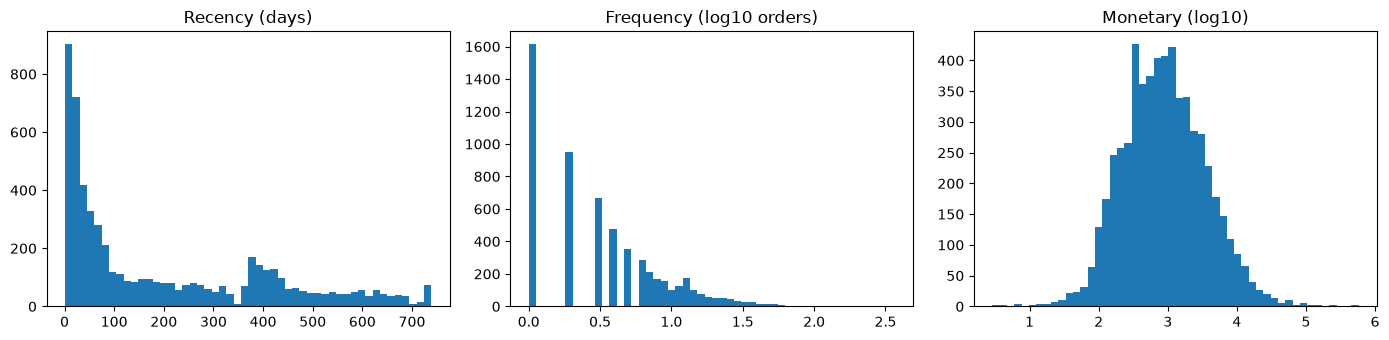

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))

axes[0].hist(rfm["recency"], bins=50)
axes[0].set_title("Recency (days)")

axes[1].hist(np.log10(rfm["frequency"]), bins=50)
axes[1].set_title("Frequency (log10 orders)")

axes[2].hist(np.log10(rfm["monetary"]), bins=50)
axes[2].set_title("Monetary (log10)")

plt.tight_layout()
plt.show()

Recency has a large group of recent buyers (median 96 days) and a long tail: 25% of customers have not bought for more than 380 days. On a log scale, frequency and monetary look roughly bell-shaped, confirming the skew in raw values.

## 3. RFM scores

In [5]:
rfm["R"] = pd.qcut(rfm["recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm.loc[rfm["frequency"] == 1, "F"] = 1# every one-time buyer gets F=1
rfm["M"] = pd.qcut(rfm["monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm["RFM"] = rfm["R"].astype(str) + rfm["F"].astype(str) + rfm["M"].astype(str)

print(rfm[["R", "F", "M"]].apply(pd.Series.value_counts))
rfm.head()

      R     F     M
1  1165  1613  1168
2  1170   723  1168
3  1160  1167  1167
4  1132  1168  1168
5  1212  1168  1168


,recency,frequency,monetary,R,F,M,RFM
Customer ID,,,,,,,
12346,530,2,169.36,1,2,1,121
12347,3,8,4921.53,5,4,5,545
12348,76,5,1658.40,3,4,4,344
12349,19,3,3678.69,5,3,5,535
12350,311,1,294.40,2,1,2,212


Quantiles put 20% of customers in each score, but 27.6% are one time buyers, so ~450 of them received F=2 only because of row order. All one-time buyers were set to F=1 (1,613 customers), so F=1 means exactly "bought once".

## 4. Segments

In [6]:
segment_map = {
    r"[1-2][1-2]": "Hibernating",
    r"[1-2][3-4]": "At Risk",
    r"[1-2]5":     "Can't Lose",
    r"3[1-2]":     "About to Sleep",
    r"33":         "Need Attention",
    r"[3-4][4-5]": "Loyal",
    r"41":         "Promising",
    r"51":         "New Customers",
    r"[4-5][2-3]": "Potential Loyalists",
    r"5[4-5]":     "Champions",
}

rfm["RF"] = rfm["R"].astype(str) + rfm["F"].astype(str)
rfm["segment"] = rfm["RF"].replace(segment_map, regex=True)

print("Unmapped:", (~rfm["segment"].isin(segment_map.values())).sum())
print("Corr F vs M:", round(rfm[["frequency", "monetary"]].corr(method="spearman").iloc[0, 1], 2))

Unmapped: 0
Corr F vs M: 0.86


Segments use the standard R x F map (10 segments, all 25 combinations covered). Monetary is not part of the definition because it moves with frequency (Spearman p = 0.86): it is used to measure each segment's value instead.

In [7]:
seg = (rfm.groupby("segment")
          .agg(customers=("recency", "size"),
               recency_med=("recency", "median"),
               frequency_med=("frequency", "median"),
               monetary_med=("monetary", "median"),
               revenue=("monetary", "sum"))
          .sort_values("revenue", ascending=False))
seg["cust_share_%"] = (seg["customers"] / seg["customers"].sum() * 100).round(1)
seg["rev_share_%"]  = (seg["revenue"] / seg["revenue"].sum() * 100).round(1)
seg.round(0)

,customers,recency_med,frequency_med,monetary_med,revenue,cust_share_%,rev_share_%
segment,,,,,,,
Champions,852,9.0,11.0,3837.0,8669090.0,15.0,53.0
Loyal,1131,54.0,8.0,2457.0,4550767.0,19.0,28.0
At Risk,751,377.0,3.0,921.0,943133.0,13.0,6.0
Hibernating,1511,433.0,1.0,271.0,647901.0,26.0,4.0
Potential Loyalists,637,24.0,3.0,706.0,592549.0,11.0,4.0
Can't Lose,73,312.0,11.0,3575.0,486539.0,1.0,3.0
Need Attention,266,107.0,3.0,926.0,294407.0,5.0,2.0
About to Sleep,380,93.0,1.0,358.0,202251.0,6.0,1.0
Promising,161,39.0,1.0,225.0,53370.0,3.0,0.0


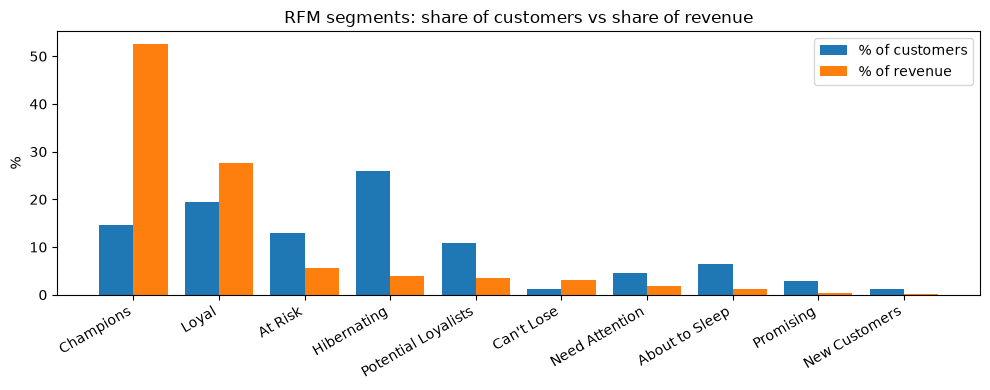

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(seg))
ax.bar(x - 0.2, seg["cust_share_%"], width=0.4, label="% of customers")
ax.bar(x + 0.2, seg["rev_share_%"],  width=0.4, label="% of revenue")
ax.set_xticks(x)
ax.set_xticklabels(seg.index, rotation=30, ha="right")
ax.set_ylabel("%")
ax.set_title("RFM segments: share of customers vs share of revenue")
ax.legend()
plt.tight_layout()
plt.show()

Champions are 14.6% of customers but 52.6% of revenue; with Loyal, 34% of customers generate 80% of revenue, so retention effort goes there first. At Risk + Can't Lose are 824 customers (14%)  with 8.7% of revenue: formerly good customers who stopped buying. Can't Lose (73 customers, median 11 orders, 3,575) is the clearest win-back target. Hibernating is the largest segment (25.9%) but only 3.9% of revenue, so it gets cheap automated contact only. Note: monetary is past two-year revenue, not a forecast of future value.

## 5. Actions

In [9]:
actions = {
    "Champions":           "Reward & retain: early access, loyalty perks; ask for referrals",
    "Loyal":               "Upsell / cross-sell (basket rules), volume discounts",
    "Potential Loyalists": "Nudge to repeat: 2nd-order offer, product recommendations",
    "New Customers":       "Onboarding: welcome series, best-sellers",
    "Promising":           "Build habit: limited-time offer on related products",
    "Need Attention":      "Personalised reactivation before they slip further",
    "About to Sleep":      "Low-cost reminder: new arrivals, seasonal campaign",
    "At Risk":             "Win-back campaign with targeted offer",
    "Can't Lose":          "Personal outreach (account manager call), strong win-back offer",
    "Hibernating":         "Cheap automated email only; don't spend budget",
}
seg["action"] = seg.index.map(actions)
seg[["customers", "cust_share_%", "rev_share_%", "action"]]

,customers,cust_share_%,rev_share_%,action
segment,,,,
Champions,852,14.6,52.6,"Reward & retain: early access, loyalty perks; ask for referrals"
Loyal,1131,19.4,27.6,"Upsell / cross-sell (basket rules), volume discounts"
At Risk,751,12.9,5.7,Win-back campaign with targeted offer
Hibernating,1511,25.9,3.9,Cheap automated email only; don't spend budget
Potential Loyalists,637,10.9,3.6,"Nudge to repeat: 2nd-order offer, product recommendations"
Can't Lose,73,1.3,3.0,"Personal outreach (account manager call), strong win-back offer"
Need Attention,266,4.6,1.8,Personalised reactivation before they slip further
About to Sleep,380,6.5,1.2,"Low-cost reminder: new arrivals, seasonal campaign"
Promising,161,2.8,0.3,Build habit: limited-time offer on related products


In a bank, Recency = days since last transaction or login, Frequency = transactions per month, Monetary = balances or income generated. Champions resemble primary-bank customers; At Risk and Can't Lose are early attrition signals, the population a churn model (Project 1) would score; Hibernating are dormant accounts. The action column works like a CRM campaign plan: each segment gets a different channel and budget.

## 6. Save

In [10]:
OUT = PROJECT_DIR / "data" / "processed" / "rfm_segments.parquet"
rfm.reset_index().to_parquet(OUT, index=False)
print("Saved:", OUT.name, rfm.shape)

Saved: rfm_segments.parquet (5839, 9)
